# Pharaohs of Egypt: three thousand years in three tables

What the pipeline in this repo produces, read back and drawn: every ruler Wikidata records as a pharaoh, the dynasties they belong to with the conventional chronology, and the pyramids they built. The point of the notebook is to show what the data can and cannot say: Wikidata knows the dynasty of three quarters of the pharaohs but has reign dates for only a sixth of them, which is why the dynasty-level chronology is curated by hand.

*Omar Essam El Sherbiny · [omaressam.web.app](https://omaressam.web.app) · [github.com/engomaressam/pharaohs-of-egypt](https://github.com/engomaressam/pharaohs-of-egypt)*

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FIG = Path('figures'); FIG.mkdir(exist_ok=True)
BLUE, ORANGE, INK, MUTED, GRID = '#2a78d6', '#eb6834', '#262626', '#898781', '#e1e0d9'
plt.rcParams.update({'font.size': 12, 'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': INK, 'xtick.color': MUTED, 'ytick.color': MUTED,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID, 'axes.axisbelow': True,
                     'axes.titlesize': 14, 'axes.titleweight': 'bold', 'savefig.dpi': 200, 'savefig.bbox': 'tight'})
pharaohs = pd.read_csv('data/pharaohs.csv')
dynasties = pd.read_csv('data/dynasties.csv')
pyramids = pd.read_csv('data/pyramids.csv')
print(f"{len(pharaohs)} pharaohs | {pharaohs['dynasty'].notna().sum()} with a dynasty | {pharaohs['reign_start_year'].notna().sum()} with a reign start | "
      f"{pharaohs['image_url'].notna().sum()} with an image\n{len(dynasties)} dynasties | {len(pyramids)} pyramids, {pyramids['latitude'].notna().sum()} with coordinates")

513 pharaohs | 384 with a dynasty | 76 with a reign start | 302 with an image
38 dynasties | 84 pyramids, 78 with coordinates


## 1. The dynasties, as conventionally dated, and how many pharaohs Wikidata assigns to each

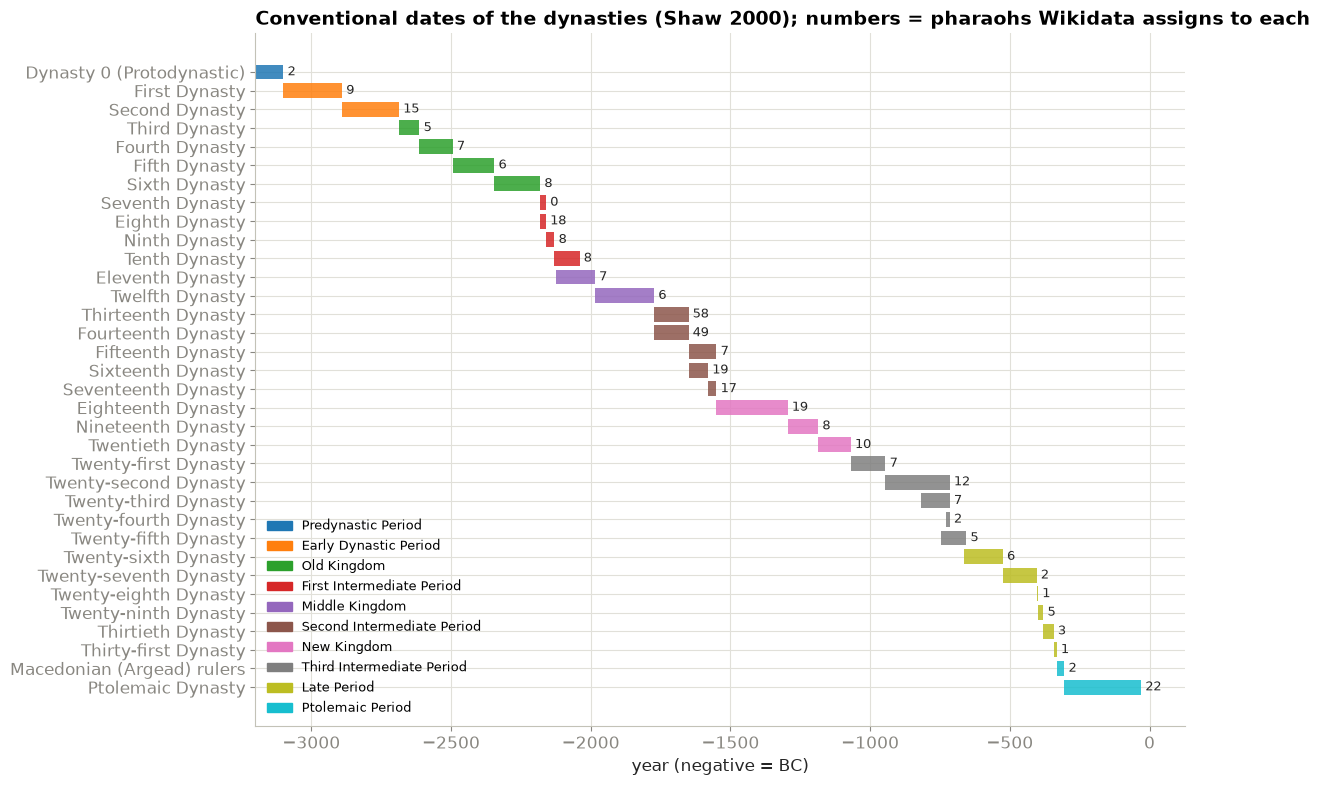

,dynasty_number,dynasty,period,start_bc,end_bc,n_pharaohs
0,0.0,Dynasty 0 (Protodynastic),Predynastic Period,3200.0,3100.0,2
1,1.0,First Dynasty,Early Dynastic Period,3100.0,2890.0,9
2,2.0,Second Dynasty,Early Dynastic Period,2890.0,2686.0,15
3,3.0,Third Dynasty,Old Kingdom,2686.0,2613.0,5
4,4.0,Fourth Dynasty,Old Kingdom,2613.0,2494.0,7
5,5.0,Fifth Dynasty,Old Kingdom,2494.0,2345.0,6
6,6.0,Sixth Dynasty,Old Kingdom,2345.0,2181.0,8
7,7.0,Seventh Dynasty,First Intermediate Period,2181.0,2160.0,0
8,8.0,Eighth Dynasty,First Intermediate Period,2181.0,2160.0,18
9,9.0,Ninth Dynasty,First Intermediate Period,2160.0,2130.0,8


In [2]:
d = dynasties.dropna(subset=['dynasty_number', 'start_bc']).copy()
d['n_pharaohs'] = d['dynasty_number'].map(pharaohs['dynasty_number'].value_counts()).fillna(0).astype(int)
periods = list(dict.fromkeys(d['period']))
colors = dict(zip(periods, plt.cm.tab10(np.linspace(0, 1, len(periods)))))
fig, ax = plt.subplots(figsize=(12, 9))
for i, r in d.iterrows():
    ax.barh(r['dynasty'], r['start_bc'] - r['end_bc'], left=-r['start_bc'], color=colors[r['period']], alpha=0.85)
    ax.text(-r['end_bc'] + 15, r['dynasty'], f"{r['n_pharaohs']}", va='center', fontsize=9, color=INK)
ax.invert_yaxis()
ax.set_xlabel('year (negative = BC)')
ax.set_title('Conventional dates of the dynasties (Shaw 2000); numbers = pharaohs Wikidata assigns to each', loc='left')
handles = [plt.Rectangle((0, 0), 1, 1, color=colors[p]) for p in periods]
ax.legend(handles, periods, frameon=False, fontsize=9, loc='lower left')
plt.savefig(FIG / 'fig1_dynasties_timeline.png'); plt.show()
d[['dynasty_number', 'dynasty', 'period', 'start_bc', 'end_bc', 'n_pharaohs']].head(12)

Two things show in the bars. The Second Intermediate Period dynasties (13th to 17th) carry far more names than their years would suggest: dozens of short-lived kings known from a single scarab or king-list entry. And the Ptolemaic bar, 275 years long, holds 22 rulers (the Ptolemies plus their co-regents), a period documented year by year.

## 2. Reign lengths where Wikidata records both ends

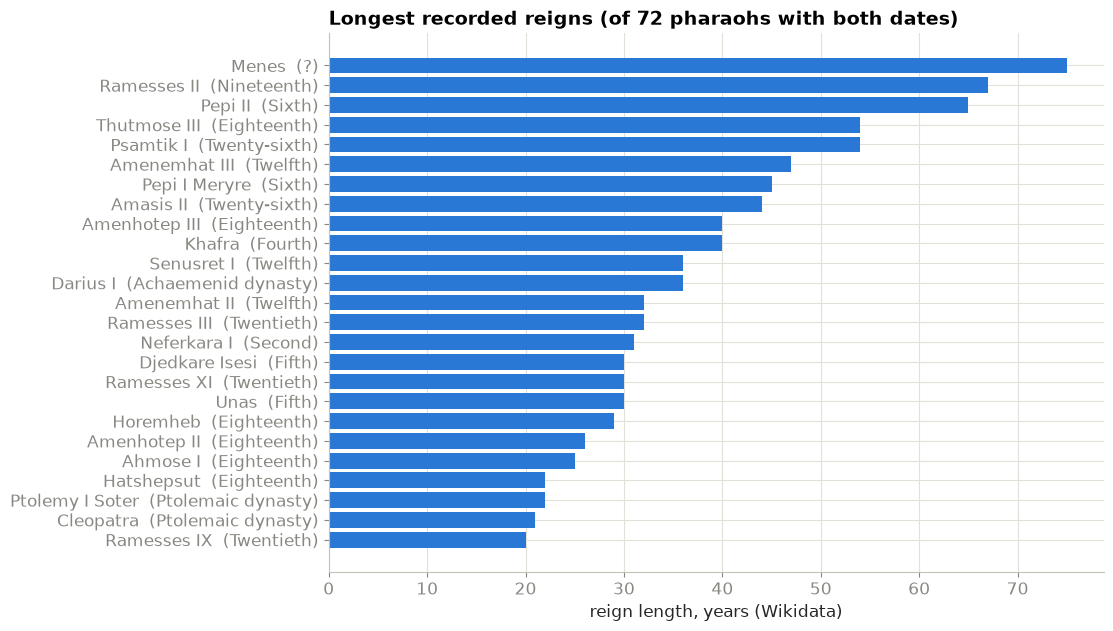

median reign where known: 10.0 years


In [3]:
r = pharaohs.dropna(subset=['reign_length_years']).query('reign_length_years > 0').sort_values('reign_length_years', ascending=False)
fig, ax = plt.subplots(figsize=(10, 7))
top = r.head(25)
ax.barh(top['name'] + '  (' + top['dynasty'].fillna('?').str.replace(' Dynasty of Egypt', '').str.replace(' of Egypt', '') + ')', top['reign_length_years'], color=BLUE)
ax.invert_yaxis(); ax.set_xlabel('reign length, years (Wikidata)')
ax.set_title(f'Longest recorded reigns (of {len(r)} pharaohs with both dates)', loc='left')
plt.savefig(FIG / 'fig2_reign_lengths.png'); plt.show()
print('median reign where known:', r['reign_length_years'].median(), 'years')

The dates come with their precision: a reign recorded to the year is one thing, one recorded to the century is another. `reign_start_precision` and `reign_end_precision` carry that flag, and the quality notes list the handful of legendary dates the pipeline refused.

## 3. The pyramids, on a map

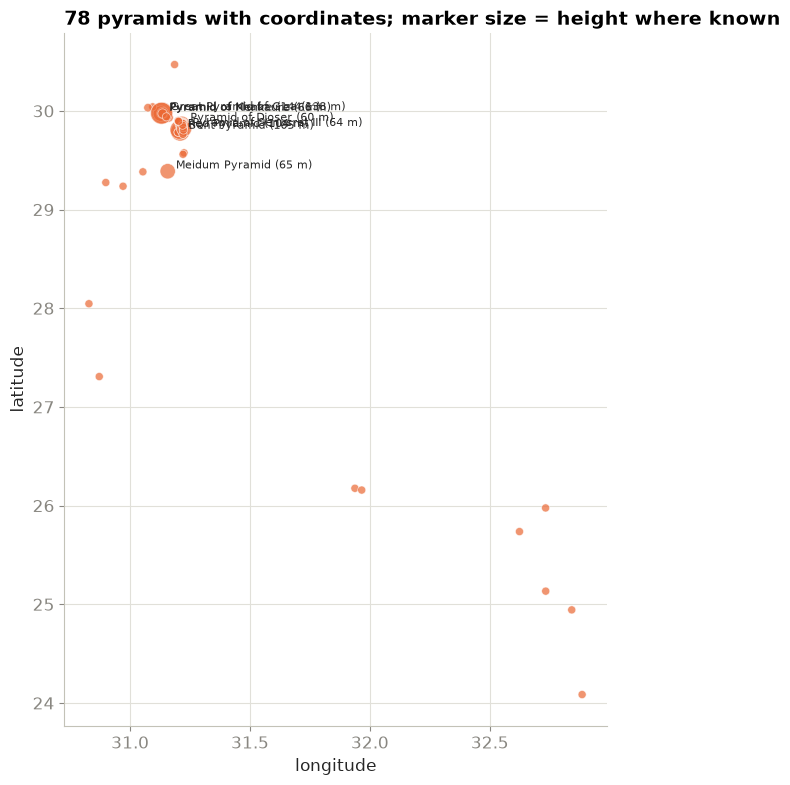

,name,built_for,location,height_m,inception_label
46,Pyramid of Khafre,Khafra,Giza,143.50,NaN
4,Great Pyramid of Giza,Khufu,Giza Governorate,137.50,2560 BC
0,Bent Pyramid,Sneferu,Giza Governorate,105.07,2700 BC
3,Red Pyramid,Sneferu,Giza Governorate,104.00,2590 BC
5,Pyramid of Menkaure,NaN,Giza,65.55,2511 BC
2,Meidum Pyramid,Huni,Beni Suef Governorate,65.00,2611 BC
69,Pyramid of Senusret III,Senusret III,NaN,64.00,NaN
1,Pyramid of Djoser,Djoser,Giza Governorate,60.00,2640 BC
38,Pyramid of Djedkare-Isesi,Djedkare Isesi,NaN,52.50,NaN
7,Pyramid of Unas,Unas,Giza Governorate,43.00,2360 BC


In [4]:
p = pyramids.dropna(subset=['latitude', 'longitude']).copy()
fig, ax = plt.subplots(figsize=(7, 9))
ax.scatter(p['longitude'], p['latitude'], s=18 + p['height_m'].fillna(10) * 1.6, color=ORANGE, alpha=0.7, edgecolor='white', lw=0.5)
for _, q in p.dropna(subset=['height_m']).sort_values('height_m', ascending=False).head(8).iterrows():
    ax.annotate(f"{q['name']} ({q['height_m']:.0f} m)", (q['longitude'], q['latitude']), xytext=(6, 2), textcoords='offset points', fontsize=8, color=INK)
ax.set_xlabel('longitude'); ax.set_ylabel('latitude')
ax.set_title(f'{len(p)} pyramids with coordinates; marker size = height where known', loc='left')
plt.savefig(FIG / 'fig3_pyramids_map.png'); plt.show()
pyramids.dropna(subset=['height_m']).sort_values('height_m', ascending=False)[['name', 'built_for', 'location', 'height_m', 'inception_label']].head(10)

Almost everything sits on a 100 km stretch of the west bank between Abu Rawash and Meidum, where the Old Kingdom buried its kings within sight of the capital at Memphis. The outliers further south are Middle Kingdom and Nubian.

## 4. What is missing, honestly

- Wikidata has a dynasty for 384 of 513 pharaohs and reign dates for 76; the rest are known from king lists without dates, or have dates only at century precision.
- The conventional chronology in `data/reference/dynasties_conventional.csv` is one of several (Shaw 2000); absolute dates before the New Kingdom carry an uncertainty of decades to a century.
- Coverage of pyramids with recorded heights is thin (17 of 84); heights for the rest exist in the literature but not yet in Wikidata.

If you add or correct data upstream in Wikidata, re-running `pipeline/extract.py` and `pipeline/build.py` picks it up.